# 05 — Uncertainty, stability and out-of-distribution generalisation

Four ways of attaching uncertainty to an identified model:

| | model | source of spread |
|---|---|---|
| **E-SINDy** | weak SINDy | bootstrap over the rows of the weak regression ($B=100$) |
| **N2-bag** | sparse NODE | bootstrap over shooting windows, 5 members |
| **N1-ens** | black-box NODE | deep ensemble, 5 independent initialisations and minibatch streams |
| **N1-MC** | black-box NODE | Monte Carlo dropout ($p=0.1$), masks frozen along each trajectory, 30 samples |

Each predictive distribution is scored on 16 in-distribution initial conditions (on the attractor) and 16 out-of-distribution ones (at least 2 standard deviations from it), at two noise levels.

In [1]:
import sys, os, time, pickle
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from src import experiment as E, plotting as P, metrics as M
from src.sweeps import neural_job, run_parallel
from src.library import PolyLibrary
from src.sindy import fit_weak_sindy, esindy, poly_field
from src.integrators import rollout_np
from src.node import rollout_model
P.setup()
MET = "../results/metrics"
torch.set_num_threads(2)
CASES = [(name, 1/15, eps) for name in ["lorenz", "lv4"] for eps in [0.01, 0.10]]
M_ENS = 5

In [2]:
jobs = []
for (name, r, eps) in CASES:
    jobs += [(name, r, eps, 0, "N1-MLP", dict(train_seed=k, tag_extra=f"_ens{k}", evaluate=False)) for k in range(1, M_ENS)]
    jobs += [(name, r, eps, 0, "N2-Lib", dict(train_seed=k, tag_extra=f"_bag{k}", bootstrap=True, evaluate=False)) for k in range(M_ENS)]
    jobs += [(name, r, eps, 0, "N1-MLP", dict(p_drop=0.1, tag_extra="_drop", evaluate=False))]
    jobs += [(name, r, eps, 0, "N1-MLP", dict(evaluate=False))]          # member 0 = sweep model
print(len(jobs), "trainings (cached ones are loaded)")
t0 = time.time()
rows = run_parallel(neural_job, jobs, workers=2, log_every=10)
print(f"{(time.time() - t0) / 60:.1f} min;", sum("error" in r for r in rows), "failures")

44 trainings (cached ones are loaded)


10/44 jobs done


20/44 jobs done


30/44 jobs done


40/44 jobs done


44/44 jobs done


0.1 min; 0 failures


## Predictive ensembles

In [3]:
def forecasts(name, r, eps, n_steps=None):
    s = E.get_sys(name); ref = E.reference(name)
    h = float(ref["h"]); n = n_steps or int(ref["n_steps"])
    lib = PolyLibrary(s.d, 2, s.symbols)
    ds = E.make_dataset(name, r, eps, 0); nd = E.nondim_for(ds, lib)
    X0 = {tag: ref[f"X0_{tag}"] for tag in ("id", "ood")}
    out, coef = {}, {}
    # E-SINDy
    Xi_w, info = fit_weak_sindy(ds["fit"], nd, ds["val"], h, s.t_char, return_system=True)
    G, B = info["system"]
    samples, incl, med = esindy(G, B, nd, info["lam"], n_boot=100, rng=np.random.default_rng(0))
    coef["E-SINDy"] = samples
    sel = np.random.default_rng(1).choice(len(samples), 30, replace=False)
    out["E-SINDy"] = {tag: np.stack([rollout_np(poly_field(lib, samples[b]), X0[tag], n, h) for b in sel])
                      for tag in X0}
    # N2 bagging
    mods = [E.run_neural(name, r, eps, 0, "N2-Lib", train_seed=k, tag_extra=f"_bag{k}", bootstrap=True,
                         evaluate=False) for k in range(M_ENS)]
    coef["N2-bag"] = np.stack([m[0]["Xi"] for m in mods])
    out["N2-bag"] = {tag: np.stack([rollout_np(poly_field(lib, m[0]["Xi"]), X0[tag], n, h) for m in mods]) for tag in X0}
    # N1 deep ensemble
    mods = [E.run_neural(name, r, eps, 0, "N1-MLP", evaluate=False)] + \
           [E.run_neural(name, r, eps, 0, "N1-MLP", train_seed=k, tag_extra=f"_ens{k}", evaluate=False) for k in range(1, M_ENS)]
    out["N1-ens"] = {tag: np.stack([rollout_model(m[1], X0[tag], n, h) for m in mods]) for tag in X0}
    # N1 MC dropout
    _, mdrop, _ = E.run_neural(name, r, eps, 0, "N1-MLP", p_drop=0.1, tag_extra="_drop", evaluate=False)
    gen = torch.Generator().manual_seed(0)
    out["N1-MC"] = {tag: np.stack([rollout_model(mdrop, X0[tag], n, h, masks_batch=True, generator=gen)
                                   for _ in range(30)]) for tag in X0}
    return out, coef, ref, s

t0 = time.time()
FC = {}
for case in CASES:
    FC[case] = forecasts(*case)
    print(case, f"{time.time() - t0:.0f} s")

('lorenz', 0.06666666666666667, 0.01) 89 s


('lorenz', 0.06666666666666667, 0.1) 176 s


('lv4', 0.06666666666666667, 0.01) 259 s


('lv4', 0.06666666666666667, 0.1) 373 s


In [4]:
def uq_scores(samples, truth, std, t, unit, lead_max=5.0):
    # samples (M, T, B, d), truth (T, B, d); lead times up to lead_max Lyapunov times
    k = t * unit <= lead_max
    Sm = samples[:, k] / std; Tr = truth[k] / std
    finite = np.isfinite(Sm).all(axis=(1, 3))                       # (M, B) members that stayed bounded
    frac_div = 1 - finite.mean()
    Sm = np.where(np.isfinite(Sm), Sm, np.nan)
    cover = M.interval_coverage(Sm, Tr).mean(axis=(1, 2))           # (T,)
    crps = np.nanmean(M.ensemble_crps(Sm, Tr), axis=(1, 2))         # (T,)
    mean = np.nanmean(Sm, axis=0); spread = np.nanstd(Sm, axis=0)
    err = np.abs(mean - Tr)
    ok = np.isfinite(spread) & np.isfinite(err)
    rho = spearmanr(spread[ok].ravel(), err[ok].ravel()).statistic if ok.sum() > 10 else np.nan
    k1 = np.searchsorted(t[k] * unit, 1.0)
    return dict(coverage=float(np.nanmean(cover)), crps=float(np.nanmean(crps)), spread_skill=float(rho),
                spread_1lyap=float(np.nanmean(spread[:k1 + 1])), err_1lyap=float(np.nanmean(err[:k1 + 1])),
                member_divergence=float(frac_div)), cover, crps

rows, curves = [], {}
for (name, r, eps), (out, coef, ref, s) in FC.items():
    t = float(ref["h"]) * np.arange(ref["X_id"].shape[0]); unit = E.time_unit(s)
    for meth, d in out.items():
        for tag in ("id", "ood"):
            sc, cov, crps = uq_scores(d[tag], ref[f"X_{tag}"], ref["std"], t, unit)
            rows.append(dict(system=name, noise=eps, method=meth, ic=tag, **sc))
            curves[(name, eps, meth, tag)] = (t[: len(cov)] * unit, cov, crps)
uq = pd.DataFrame(rows)
uq.to_csv(f"{MET}/uq_summary.csv", index=False)
uq.pivot_table(index=["system", "noise", "method"], columns="ic",
               values=["coverage", "crps", "spread_skill", "spread_1lyap", "err_1lyap"]).round(3)

/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/home/claude/sparse-chaos-discovery/src/metrics.py:90: RuntimeWarning: Mean of empty slice
  t1 = np.nanmean(np.abs(samples - y[None]), axis=0)
/tmp/ipykernel_7640/1228707267.py:10: RuntimeWarning: Mean of empty slice
  mean = np.nanmean(Sm, axis=0); spread = np.nanstd(Sm, axis=0)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


coverage          crps        err_1lyap          \
ic                         id    ood     id    ood        id     ood   
system noise method                                                    
lorenz 0.01  E-SINDy    0.866  0.930  0.158  0.217     0.009   0.190   
             N1-MC      0.671  0.644  0.643  0.955     0.471   2.474   
             N1-ens     0.414  0.471  0.507  1.354     0.132   3.113   
             N2-bag     0.185  0.115  0.102  0.073     0.005   0.032   
       0.10  E-SINDy    0.752  0.758  0.424  0.782     0.118   1.265   
             N1-MC      0.682  0.648  0.620  0.888     0.458   2.240   
             N1-ens     0.400  0.468  0.500  0.992     0.126   2.234   
             N2-bag     0.540  0.493  0.328  0.589     0.044   0.630   
lv4    0.01  E-SINDy    0.946  0.953  0.574  3.314     0.207   5.314   
             N1-MC      0.735  0.407  0.563  1.764     0.562   2.399   
             N1-ens     0.381  0.470  0.654  2.648     0.388   2.645   
             N2-bag     0.575  0.352  0.325  3.109     0.043   6.146   
       0.10  E-SINDy    0.846  0.829  6.904  8.491    21.990  25.985   
             N1-MC      0.666  0.510  0.553  1.811     0.548   2.302   
             N1-ens     0.363  0.497  0.657  2.463     0.390   2.541   
             N2-bag     0.505  0.166  0.650  9.963     0.214  61.177   

                     spread_1lyap          spread_skill         
ic                             id      ood           id    ood  
system noise method                                             
lorenz 0.01  E-SINDy        0.016    0.247        0.886  0.806  
             N1-MC          0.456    0.507        0.205 -0.092  
             N1-ens         0.060    0.715        0.613  0.126  
             N2-bag         0.001    0.003        0.793  0.796  
       0.10  E-SINDy        0.177    1.984        0.582  0.344  
             N1-MC          0.457    0.476        0.233 -0.143  
             N1-ens         0.056    0.549        0.620 -0.119  
             N2-bag         0.038    0.445        0.768  0.326  
lv4    0.01  E-SINDy        0.198   21.792        0.679  0.528  
             N1-MC          0.354    0.627        0.127  0.148  
             N1-ens         0.081    0.598        0.253  0.104  
             N2-bag         0.052    6.555        0.755  0.351  
       0.10  E-SINDy       89.908  104.188        0.564  0.244  
             N1-MC          0.332    0.656        0.123  0.144  
             N1-ens         0.094    0.675        0.260  0.045  
             N2-bag         0.130   27.180        0.474  0.278

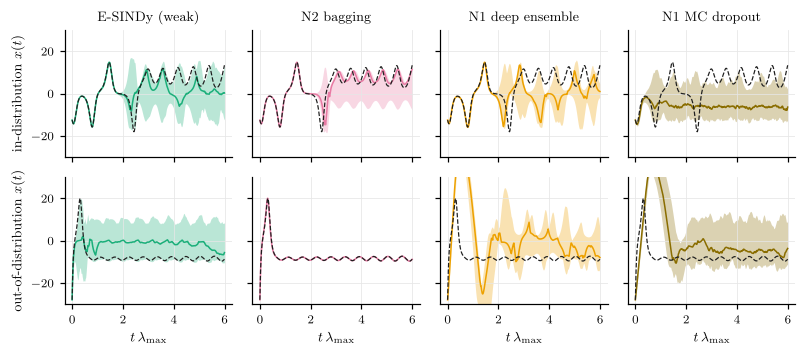

In [5]:
UQC = {"E-SINDy": P.COLORS["C3-WSINDy"], "N2-bag": P.COLORS["N2-Lib"], "N1-ens": P.COLORS["N1-MLP"], "N1-MC": "#8a6d00"}
UQL = {"E-SINDy": "E-SINDy (weak)", "N2-bag": "N2 bagging", "N1-ens": "N1 deep ensemble", "N1-MC": "N1 MC dropout"}
name, eps = "lorenz", 0.01
out, coef, ref, s = FC[(name, 1/15, eps)]
t = float(ref["h"]) * np.arange(ref["X_id"].shape[0]) * s.lyap
kmax = np.searchsorted(t, 6.0)
fig, axes = plt.subplots(2, 4, figsize=(7.4, 3.3), sharex=True, sharey="row")
for i, (tag, b) in enumerate([("id", 3), ("ood", 5)]):
    for j, meth in enumerate(UQC):
        ax = axes[i, j]
        S = out[meth][tag][:, :kmax, b, 0]
        lo, hi = np.nanpercentile(S, [5, 95], axis=0)
        ax.fill_between(t[:kmax], lo, hi, color=UQC[meth], alpha=0.3, lw=0)
        ax.plot(t[:kmax], np.nanmedian(S, axis=0), color=UQC[meth], lw=1.0)
        ax.plot(t[:kmax], ref[f"X_{tag}"][:kmax, b, 0], color=P.COLORS["truth"], lw=0.8, ls="--")
        if i == 0: ax.set_title(UQL[meth])
        if i == 1: ax.set_xlabel(r"$t\,\lambda_{\max}$")
        if j == 0: ax.set_ylabel(("in-distribution" if tag == "id" else "out-of-distribution") + r"  $x(t)$")
        ax.set_ylim(-30, 30)
fig.tight_layout()
P.save(fig, "fig05_uq_bands")
plt.show()

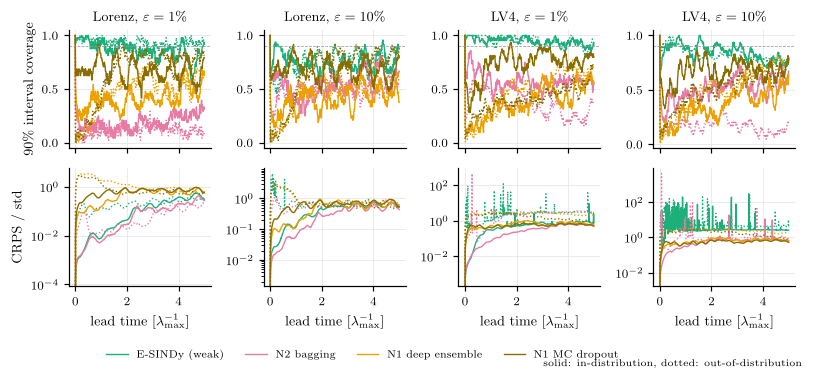

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(7.4, 3.4), sharex=True)
for j, (name, eps) in enumerate([("lorenz", 0.01), ("lorenz", 0.10), ("lv4", 0.01), ("lv4", 0.10)]):
    for meth in UQC:
        for tag, ls in [("id", "-"), ("ood", ":")]:
            tt, cov, crps = curves[(name, eps, meth, tag)]
            axes[0, j].plot(tt, cov, ls, color=UQC[meth], lw=0.9, label=UQL[meth] if tag == "id" else None)
            axes[1, j].semilogy(tt, crps, ls, color=UQC[meth], lw=0.9)
    axes[0, j].axhline(0.9, color="#999999", lw=0.5, ls="--")
    axes[0, j].set_title(("Lorenz" if name == "lorenz" else "LV4") + rf", $\varepsilon={int(eps*100)}\%$")
    axes[1, j].set_xlabel(r"lead time [$\lambda_{\max}^{-1}$]")
axes[0, 0].set_ylabel("90\\% interval coverage"); axes[1, 0].set_ylabel("CRPS / std")
h, l = axes[0, 0].get_legend_handles_labels()
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.legend(h, l, loc="lower center", ncol=4, frameon=False, fontsize=7, bbox_to_anchor=(0.45, 0.0))
fig.text(0.99, 0.01, "solid: in-distribution, dotted: out-of-distribution", ha="right", fontsize=6.5)
P.save(fig, "fig05_uq_calibration")
plt.show()

## Coefficient uncertainty: inclusion probabilities

$P(\xi_{kj}\neq 0)$ under the E-SINDy bootstrap, at $\Delta t_{\rm obs}=t_{\rm char}/15$ across noise levels (Lorenz). True terms are outlined.

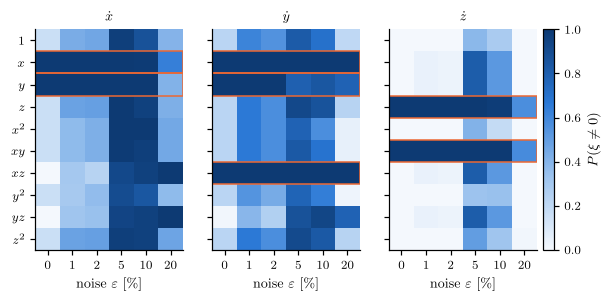

In [7]:
s = E.get_sys("lorenz"); lib = PolyLibrary(3, 2, s.symbols); h = 0.01
probs = []
for eps in E.NOISES:
    ds = E.make_dataset("lorenz", 1/15, eps, 0); nd = E.nondim_for(ds, lib)
    Xi_w, info = fit_weak_sindy(ds["fit"], nd, ds["val"], h, s.t_char, return_system=True)
    _, incl, _ = esindy(*info["system"], nd, info["lam"], n_boot=100, rng=np.random.default_rng(0))
    probs.append(incl)
probs = np.array(probs)          # (noise, p, d)
fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.6), sharey=True)
for j, ax in enumerate(axes):
    im = ax.imshow(probs[:, :, j].T, cmap=P.SEQ, vmin=0, vmax=1, aspect="auto")
    for k in range(lib.n_terms):
        if s.Xi_true[k, j] != 0:
            ax.add_patch(plt.Rectangle((-0.5, k - 0.5), len(E.NOISES), 1, fill=False, ec="#eb6834", lw=1.0))
    ax.set_xticks(range(len(E.NOISES))); ax.set_xticklabels([f"{int(100*e)}" for e in E.NOISES])
    ax.set_xlabel(r"noise $\varepsilon$ [\%]"); ax.set_title(rf"$\dot {s.symbols[j]}$"); ax.grid(False)
axes[0].set_yticks(range(lib.n_terms)); axes[0].set_yticklabels([rf"${n}$" if n != "1" else "$1$" for n in lib.names])
fig.colorbar(im, ax=axes, pad=0.01).set_label(r"$P(\xi\neq0)$")
P.save(fig, "fig05_inclusion")
plt.show()
np.save(f"{MET}/esindy_inclusion_lorenz.npy", probs)

## Spread as a detector of distribution shift

In [8]:
ratio = uq.pivot_table(index=["system", "noise", "method"], columns="ic", values="spread_1lyap")
ratio["ood/id spread"] = ratio["ood"] / ratio["id"]
err = uq.pivot_table(index=["system", "noise", "method"], columns="ic", values="err_1lyap")
ratio["ood/id error"] = err["ood"] / err["id"]
ratio.round(3).to_csv(f"{MET}/uq_shift_ratio.csv")
ratio.round(3)

ic                        id      ood  ood/id spread  ood/id error
system noise method                                               
lorenz 0.01  E-SINDy   0.016    0.247         15.435        20.879
             N1-MC     0.456    0.507          1.112         5.254
             N1-ens    0.060    0.715         11.905        23.512
             N2-bag    0.001    0.003          3.922         6.423
       0.10  E-SINDy   0.177    1.984         11.237        10.722
             N1-MC     0.457    0.476          1.040         4.890
             N1-ens    0.056    0.549          9.770        17.793
             N2-bag    0.038    0.445         11.853        14.289
lv4    0.01  E-SINDy   0.198   21.792        110.132        25.617
             N1-MC     0.354    0.627          1.770         4.267
             N1-ens    0.081    0.598          7.371         6.825
             N2-bag    0.052    6.555        125.535       142.849
       0.10  E-SINDy  89.908  104.188          1.159         1.182
             N1-MC     0.332    0.656          1.975         4.198
             N1-ens    0.094    0.675          7.201         6.516
             N2-bag    0.130   27.180        209.443       285.837